## Thanks to the SCIMBA team (E. Franck, V. Michel-Dansac, ...) https://www.scimba.org
----------------------------------------------------------------
# PINNs: linearized Euler 1D

Solves the linearized Euler equations in 1D using a PINN.

$$\left\{\begin{array}{rl}\partial_t p + \partial_x u & = f_1 \text{ in } \Omega \times (0, T) \\
    \partial_t u + \partial_x p & = f_2 \text{ in } \Omega \times (0, T) \\
    p & = g_1 \text{ on } \partial \Omega \times (0, T) \\
    u & = g_2 \text{ on } \partial \Omega \times (0, T) \\
    p & = p_0 \text{ on } \Omega \times {0} \\
    u & = u_0 \text{ on } \Omega \times {0}
\end{array}\right.$$

where $\partial \Omega \times (0, T) \to \mathbb{R}$ and $u: \partial \Omega \times (0, T) \to \mathbb{R}$ are the unknown functions, $\Omega \subset \mathbb{R}$ is the spatial domain and $(0, T) \subset \mathbb{R}$ is the time domain. Dirichlet boundary conditions are prescribed.

The equation is solved on a segment domain with a PINN with energy natural gradient preconditioning.
Weak initial conditions are used, and we compare the use of weak and strong boundary conditions.

## Using weak boundary conditions

Training: 100%|||||||||||||||| 1000/1000[01:02<00:00] , loss: 1.2e+02 -> 3.3e-05


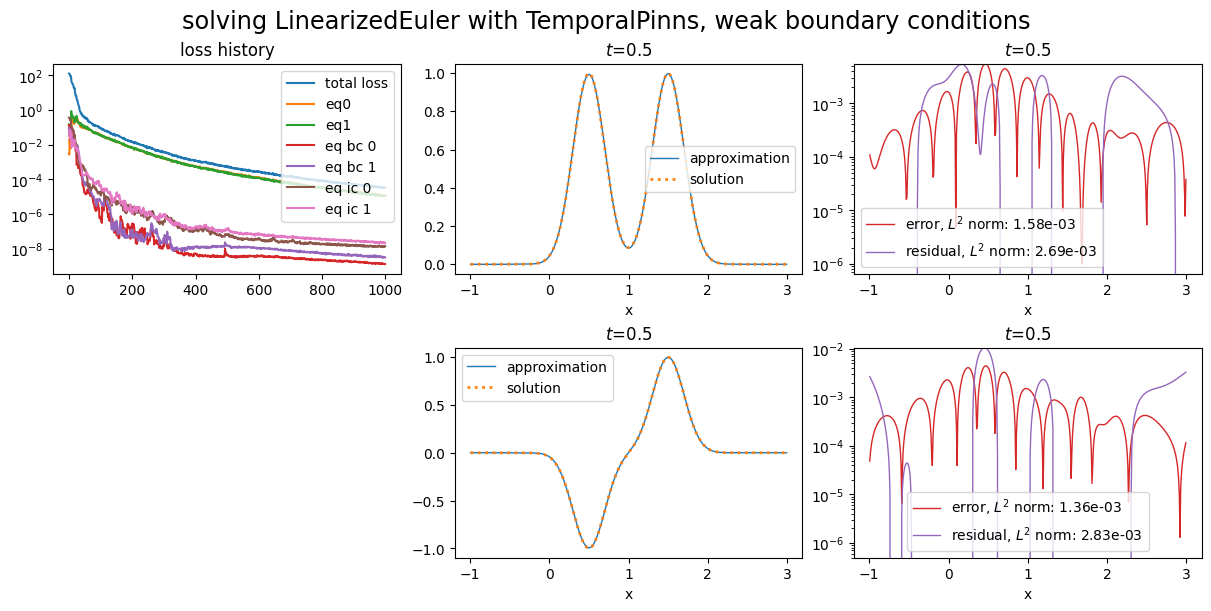

In [1]:
from typing import Callable, Tuple

import matplotlib.pyplot as plt
import torch

from scimba_torch.approximation_space.abstract_space import AbstractApproxSpace
from scimba_torch.approximation_space.nn_space import NNxtSpace
from scimba_torch.domain.meshless_domain.domain_1d import Segment1D
from scimba_torch.integration.monte_carlo import DomainSampler, TensorizedSampler
from scimba_torch.integration.monte_carlo_parameters import UniformParametricSampler
from scimba_torch.integration.monte_carlo_time import UniformTimeSampler
from scimba_torch.neural_nets.coordinates_based_nets.mlp import GenericMLP
from scimba_torch.numerical_solvers.temporal_pde.pinns import (
    AnagramTemporalPinns,
    NaturalGradientTemporalPinns,
)
from scimba_torch.plots.plots_nd import plot_abstract_approx_spaces
from scimba_torch.utils.scimba_tensors import LabelTensor, MultiLabelTensor
from scimba_torch.utils.typing_protocols import VarArgCallable


class LinearizedEuler:
    def __init__(
        self,
        space: AbstractApproxSpace,
        init: Callable,
        f: Callable,
        g: Callable,
        **kwargs,
    ):
        self.space = space
        self.init = init
        self.f = f
        self.g = g

        self.linear = True
        self.residual_size = 2
        self.bc_residual_size = 2
        self.ic_residual_size = 2

    def grad(
        self,
        w: torch.Tensor | MultiLabelTensor,
        y: torch.Tensor | LabelTensor,
    ) -> torch.Tensor | Tuple[torch.Tensor, ...]:
        return self.space.grad(w, y)

    def rhs(
        self, w: MultiLabelTensor, t: LabelTensor, x: LabelTensor, mu: LabelTensor
    ) -> Tuple[torch.Tensor]:
        return self.f(t, x, mu)

    def bc_rhs(
        self,
        w: MultiLabelTensor,
        t: LabelTensor,
        x: LabelTensor,
        n: LabelTensor,
        mu: LabelTensor,
    ) -> Tuple[torch.Tensor]:
        return self.g(t, x, mu)

    def time_operator(
        self, w: MultiLabelTensor, t: LabelTensor, x: LabelTensor, mu: LabelTensor
    ) -> Tuple[torch.Tensor]:
        p, u = w.get_components()
        p_t = self.grad(p, t)
        u_t = self.grad(u, t)

        return p_t, u_t

    def space_operator(
        self, w: MultiLabelTensor, t: LabelTensor, x: LabelTensor, mu: LabelTensor
    ) -> Tuple[torch.Tensor]:
        p, u = w.get_components()
        p_x = self.grad(p, x)
        u_x = self.grad(u, x)

        return u_x, p_x

    def functional_operator(
        self,
        func: VarArgCallable,
        t: torch.Tensor,
        x: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> torch.Tensor:
        # space operator
        pu_space = torch.func.jacrev(func, 1)(t, x, mu, theta)
        pu_space = torch.flip(pu_space, (-1,))
        # time operator
        pu_time = torch.func.jacrev(func, 0)(t, x, mu, theta)
        # sum both contributions
        return (pu_space + pu_time).squeeze()

    # Dirichlet conditions
    def bc_operator(
        self,
        w: MultiLabelTensor,
        t: LabelTensor,
        x: LabelTensor,
        n: LabelTensor,
        mu: LabelTensor,
    ) -> Tuple[torch.Tensor]:
        p, u = w.get_components()
        return p, u

    def functional_operator_bc(
        self,
        func: VarArgCallable,
        t: torch.Tensor,
        x: torch.Tensor,
        n: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> torch.Tensor:
        return func(t, x, mu, theta)

    def initial_condition(self, x: LabelTensor, mu: LabelTensor) -> Tuple[torch.Tensor]:
        return self.init(x, mu)

    def functional_operator_ic(
        self,
        func: VarArgCallable,
        x: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> Tuple[torch.Tensor]:
        t = torch.zeros_like(x)
        return func(t, x, mu, theta)


def exact_solution(t: LabelTensor, x: LabelTensor, mu: LabelTensor) -> torch.Tensor:
    x = x.get_components()
    D = 0.02
    coeff = 1 / (4 * torch.pi * D) ** 0.5
    p_plus_u = coeff * torch.exp(-((x - t.x - 1) ** 2) / (4 * D))
    p_minus_u = coeff * torch.exp(-((x + t.x - 1) ** 2) / (4 * D))
    p = (p_plus_u + p_minus_u) / 2
    u = (p_plus_u - p_minus_u) / 2
    return torch.cat((p, u), dim=-1)


def initial_solution(x: LabelTensor, mu: LabelTensor) -> Tuple[torch.Tensor]:
    sol = exact_solution(LabelTensor(torch.zeros_like(x.x)), x, mu)
    return sol[..., 0:1], sol[..., 1:2]


def f_rhs(t: LabelTensor, x: LabelTensor, mu: LabelTensor) -> Tuple[torch.Tensor]:
    x = x.get_components()
    return torch.zeros_like(x), torch.zeros_like(x)


def f_bc(t: LabelTensor, x: LabelTensor, mu: LabelTensor) -> Tuple[torch.Tensor]:
    x = x.get_components()
    return torch.zeros_like(x), torch.zeros_like(x)


domain_mu = []
domain_x = Segment1D((-1.0, 3.0), is_main_domain=True)

t_min, t_max = 0.0, 0.5
domain_t = (t_min, t_max)

sampler = TensorizedSampler(
    [
        UniformTimeSampler(domain_t),
        DomainSampler(domain_x),
        UniformParametricSampler(domain_mu),
    ]
)

bc_weight = 30.0
ic_weight = 300.0

space = NNxtSpace(2, 0, GenericMLP, domain_x, sampler, layer_sizes=[64])
pde = LinearizedEuler(space, initial_solution, f_rhs, f_bc)

pinn = NaturalGradientTemporalPinns(
    pde,
    bc_type="weak",
    ic_type="weak",
    bc_weight=bc_weight,
    ic_weight=ic_weight,
    one_loss_by_equation=True,
    matrix_regularization=1e-6,
)

pinn.solve(
    epochs=1000,
    n_collocation=3000,
    n_bc_collocation=1000,
    n_ic_collocation=1000,
    verbose=False,
)

plot_abstract_approx_spaces(
    pinn.space,
    domain_x,
    domain_mu,
    domain_t,
    time_values=[t_max],
    loss=pinn.losses,
    residual=pde,
    solution=exact_solution,
    error=exact_solution,
    title="solving LinearizedEuler with TemporalPinns, weak boundary conditions",
)

plt.show()

## Using strong boundary conditions

Training: 100%|||||||||||||||| 1000/1000[00:51<00:00] , loss: 1.0e+03 -> 7.4e-05


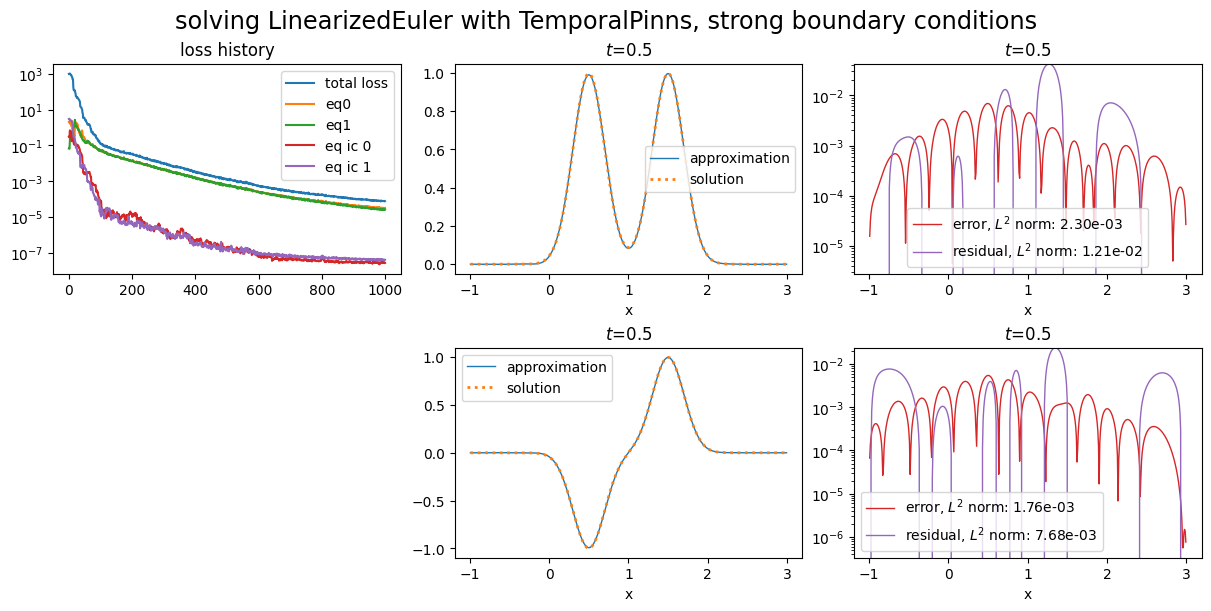

In [2]:
def post_processing(
    inputs: torch.Tensor, t: LabelTensor, x: LabelTensor, mu: LabelTensor
):
    x = x.get_components()
    # _ = mu.get_components()
    phi = (x - (-1.0)) * (x - 3.0)
    # print("inputs.shape: ", inputs.shape)
    # print("phi.shape: ", phi.shape)
    # print("res.shape: ", (inputs * phi).shape)
    return inputs * phi


def functional_post_processing(
    func, t: torch.Tensor, x: torch.Tensor, mu: torch.Tensor, theta: torch.Tensor
) -> torch.Tensor:
    phi = (x[0] - (-1.0)) * (x[0] - 3.0)
    return func(t, x, mu, theta) * phi

spaceBC = NNxtSpace(2, 0, GenericMLP, domain_x, sampler, layer_sizes=[64], post_processing=post_processing)
pdeBC = LinearizedEuler(spaceBC, initial_solution, f_rhs, f_bc)

pinnBC = NaturalGradientTemporalPinns(
    pdeBC,
    bc_type="strong",
    ic_type="weak",
    ic_weight=ic_weight,
    one_loss_by_equation=True,
    matrix_regularization=1e-6,
    functional_post_processing=functional_post_processing
)

pinnBC.solve(
    epochs=1000,
    n_collocation=3000,
    n_bc_collocation=1000,
    n_ic_collocation=1000,
    verbose=False,
)

plot_abstract_approx_spaces(
    pinnBC.space,
    domain_x,
    domain_mu,
    domain_t,
    time_values=[t_max],
    loss=pinnBC.losses,
    residual=pdeBC,
    solution=exact_solution,
    error=exact_solution,
    title="solving LinearizedEuler with TemporalPinns, strong boundary conditions"
)

plt.show()

In [ ]:
import bokeh